In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Data Loading

In [6]:
!unzip -q "/content/drive/MyDrive/image_dataset/archive.zip" -d "/content/realwaste_data"

In [7]:
import os
print(os.listdir('/content/realwaste_data'))

['realwaste-main']


In [8]:
print(os.listdir('/content/realwaste_data/realwaste-main'))

['README.md', 'RealWaste']


## Dataset Overview

In [9]:
class_dir = '/content/realwaste_data/realwaste-main/RealWaste'
classes = os.listdir(class_dir)
print(classes)

for c in classes:
    count = len(os.listdir(os.path.join(class_dir, c)))
    print(c, ':', count, 'images')

['Cardboard', 'Paper', 'Miscellaneous Trash', 'Metal', 'Textile Trash', 'Glass', 'Vegetation', 'Plastic', 'Food Organics']
Cardboard : 461 images
Paper : 500 images
Miscellaneous Trash : 495 images
Metal : 790 images
Textile Trash : 318 images
Glass : 420 images
Vegetation : 436 images
Plastic : 921 images
Food Organics : 411 images


## Data Preprocessing

In [10]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2

In [11]:
data_dir = '/content/realwaste_data/realwaste-main/RealWaste'

img_size = (224, 224)
batch_size = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=img_size,
    batch_size=batch_size
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=img_size,
    batch_size=batch_size
)

class_names = train_ds.class_names
print(class_names)

Found 4752 files belonging to 9 classes.
Using 3802 files for training.
Found 4752 files belonging to 9 classes.
Using 950 files for validation.
['Cardboard', 'Food Organics', 'Glass', 'Metal', 'Miscellaneous Trash', 'Paper', 'Plastic', 'Textile Trash', 'Vegetation']


## Sample Images

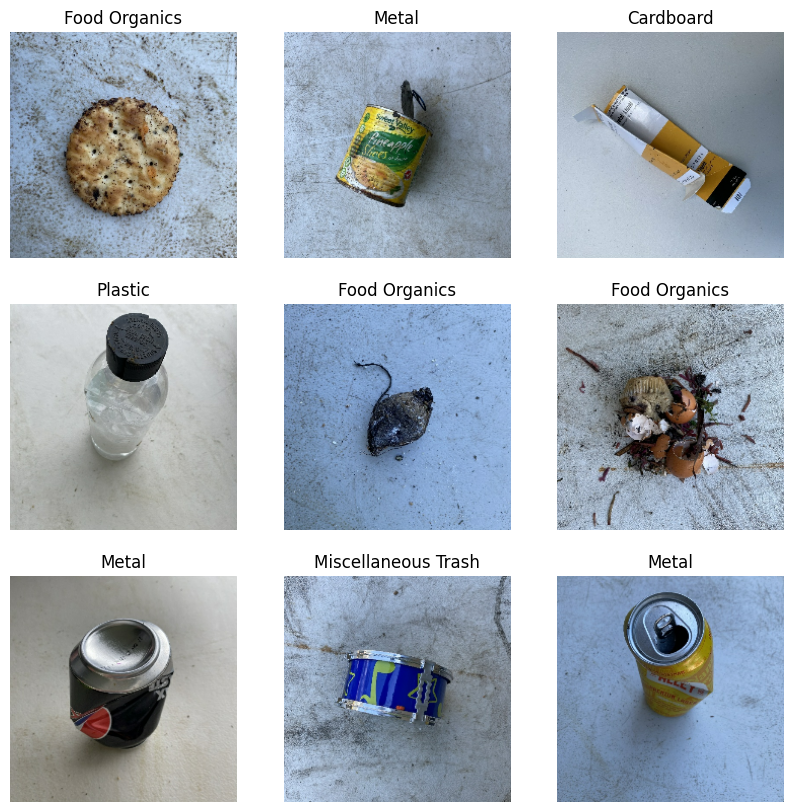

In [12]:
plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")

In [13]:
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

## Model Building (Transfer Learning with MobileNetV2)

In [14]:
base_model = MobileNetV2(input_shape=(224, 224, 3), include_top=False, weights='imagenet')
base_model.trainable = False  # freeze the pretrained layers

model = models.Sequential([
    layers.Rescaling(1./255, input_shape=(224, 224, 3)),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(9, activation='softmax')  # 9 output classes
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 9)              │         1,161 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,423,113 (9.24 MB)

 Trainable params: 165,129 (645.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## Model Training

In [15]:
epochs = 10

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epochs
)

Epoch 1/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 219s 2s/step - accuracy: 0.5752 - loss: 1.2032 - val_accuracy: 0.7400 - val_loss: 0.7062
Epoch 2/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 237s 2s/step - accuracy: 0.7454 - loss: 0.7168 - val_accuracy: 0.7737 - val_loss: 0.6235
Epoch 3/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 211s 2s/step - accuracy: 0.8017 - loss: 0.5554 - val_accuracy: 0.8053 - val_loss: 0.5571
Epoch 4/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 192s 2s/step - accuracy: 0.8382 - loss: 0.4599 - val_accuracy: 0.8116 - val_loss: 0.5085
Epoch 5/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 196s 2s/step - accuracy: 0.8724 - loss: 0.3747 - val_accuracy: 0.8242 - val_loss: 0.5004
Epoch 6/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 199s 2s/step - accuracy: 0.8948 - loss: 0.3179 - val_accuracy: 0.8263 - val_loss: 0.4940
Epoch 7/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 194s 2s/step - accuracy: 0.9111 - loss: 0.2577 - val_accuracy: 0.8389 - val_loss: 0.4858
Epoch 8/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 202s 2s/step - accuracy: 0.9303 - loss: 0.2244 - val_accu

## Training Performance

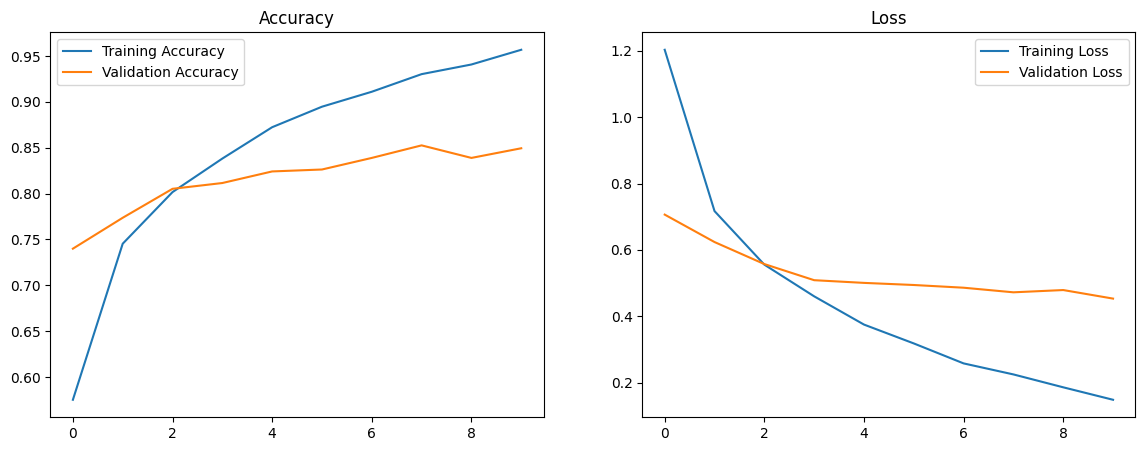

In [24]:
import matplotlib.pyplot as plt

acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(len(acc))

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend()
plt.title('Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend()
plt.title('Loss')

plt.show()

## Model Evaluation

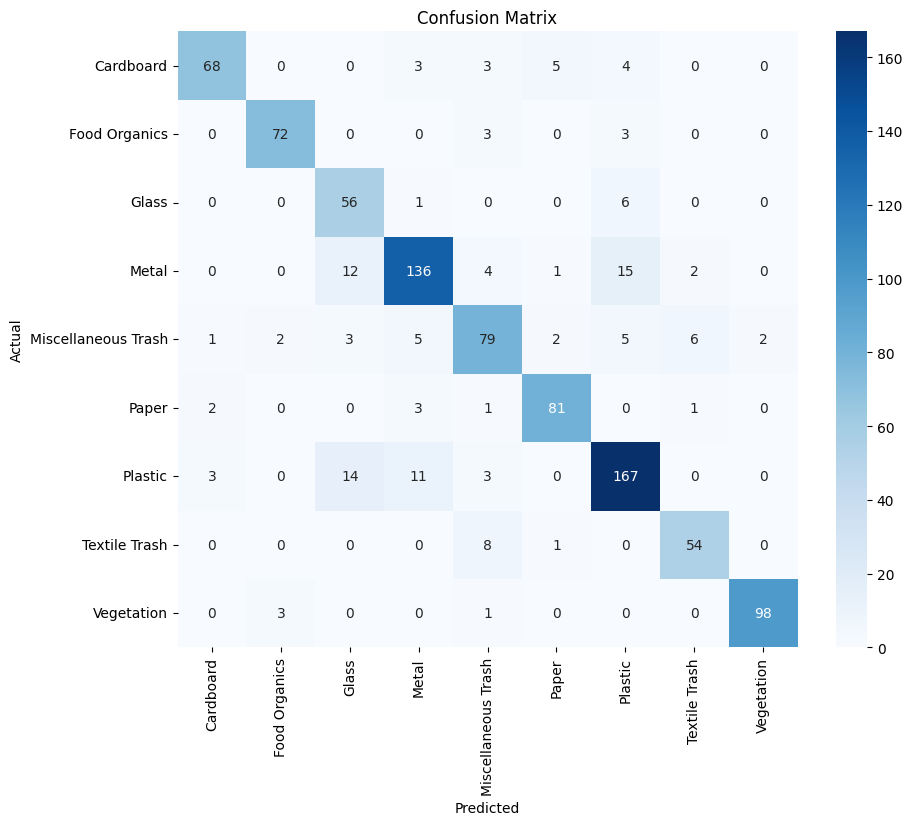

In [25]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

y_true = []
y_pred = []

for images, labels in val_ds:
    preds = model.predict(images, verbose=0)
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(labels.numpy())

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=class_names, yticklabels=class_names, cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

## Classification Report

In [26]:
print(classification_report(y_true, y_pred, target_names=class_names))

                     precision    recall  f1-score   support

          Cardboard       0.92      0.82      0.87        83
      Food Organics       0.94      0.92      0.93        78
              Glass       0.66      0.89      0.76        63
              Metal       0.86      0.80      0.83       170
Miscellaneous Trash       0.77      0.75      0.76       105
              Paper       0.90      0.92      0.91        88
            Plastic       0.83      0.84      0.84       198
      Textile Trash       0.86      0.86      0.86        63
         Vegetation       0.98      0.96      0.97       102

           accuracy                           0.85       950
          macro avg       0.86      0.86      0.86       950
       weighted avg       0.86      0.85      0.85       950



In [27]:
model.save('/content/drive/MyDrive/RealWaste/waste_classifier.h5')
print("Model saved")

Model saved


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms/step


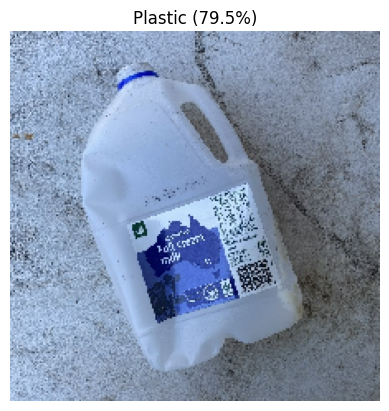

In [28]:
from tensorflow.keras.preprocessing import image

def predict_image(img_path):
    img = image.load_img(img_path, target_size=(224, 224))
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)

    pred = model.predict(img_array)
    predicted_class = class_names[np.argmax(pred)]
    confidence = np.max(pred) * 100

    plt.imshow(img)
    plt.title(f"{predicted_class} ({confidence:.1f}%)")
    plt.axis('off')
    plt.show()

# test with any image path from your dataset
predict_image('/content/realwaste_data/realwaste-main/RealWaste/Plastic/Plastic_1.jpg')

## Fine-Tuning

In [21]:
base_model.trainable = True

# Freeze all layers except the last 20
for layer in base_model.layers[:-20]:
    layer.trainable = False

model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),  # much lower learning rate
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

fine_tune_epochs = 5
history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=fine_tune_epochs
)

Epoch 1/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 243s 2s/step - accuracy: 0.7685 - loss: 0.7172 - val_accuracy: 0.8442 - val_loss: 0.5085
Epoch 2/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 242s 2s/step - accuracy: 0.8411 - loss: 0.4272 - val_accuracy: 0.8505 - val_loss: 0.4952
Epoch 3/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 256s 2s/step - accuracy: 0.8858 - loss: 0.3150 - val_accuracy: 0.8516 - val_loss: 0.4919
Epoch 4/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 239s 2s/step - accuracy: 0.9061 - loss: 0.2567 - val_accuracy: 0.8547 - val_loss: 0.4875
Epoch 5/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 236s 2s/step - accuracy: 0.9382 - loss: 0.2019 - val_accuracy: 0.8537 - val_loss: 0.4871


## Interactive Testing with Gradio

In [22]:
!pip install gradio -q

import gradio as gr

def classify_waste(img):
    img = img.resize((224, 224))
    img_array = np.expand_dims(np.array(img), axis=0)
    pred = model.predict(img_array)
    confidences = {class_names[i]: float(pred[0][i]) for i in range(len(class_names))}
    return confidences

demo = gr.Interface(
    fn=classify_waste,
    inputs=gr.Image(type="pil"),
    outputs=gr.Label(num_top_classes=3),
    title="Waste Classification",
    description="Upload an image of waste to classify it into one of 9 categories."
)

demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://20f782dd127d106c38.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [23]:
model.save('/content/drive/MyDrive/RealWaste/waste_classifier.keras', include_optimizer=False)

## Deployment

The trained model was converted to TensorFlow.js and deployed as a public website on Hugging Face Spaces. Users can upload a photo of waste and get the predicted category, a confidence score, and a disposal tip.

Live Demo: [Click here to open the website](https://khadeejajasla-waste-classifier.static.hf.space)

## Insights & Recommendations

### Key Insights

Transfer learning with MobileNetV2 reached about 85% validation accuracy across 9 waste categories. In the first training stage, only about 165K of the 2.4 million parameters were trained.

Fine-tuning the last 20 layers of MobileNetV2 improved validation accuracy slightly, from about 84% to about 85.4%.

Training accuracy reached about 94% against about 85% on validation, which shows mild overfitting. This is expected with a dataset of around 4,750 images.

Vegetation was the easiest category to recognize (precision 0.98, recall 0.95), because of its distinct color and texture.

Plastic was the hardest category (precision 0.72). The biggest confusions were Metal predicted as Plastic (26 images) and Glass predicted as Plastic (16 images), likely because of shiny, reflective and transparent surfaces.

Cardboard and Paper were also sometimes mixed up because of similar texture and color.

Textile Trash performed well (F1 0.86) even though it was the smallest class with only 318 images.

### Recommendations

Collect more Plastic, Metal and Glass images under different lighting and angles to reduce confusion between them.

Apply data augmentation (rotation, flipping, brightness changes) to reduce overfitting.

Try larger pretrained models such as EfficientNet or ResNet to see if accuracy improves, keeping in mind they are slower.

Keep the low-confidence warning in the app so users retake a clearer photo when the model is unsure.

### Limitations

The dataset photos show a single item on a plain background, so accuracy may drop on photos with cluttered backgrounds or multiple items.

Results are based on a validation split only, without a separate test set.

The confusion matrix and classification report were measured before fine-tuning, so the per-category numbers may differ slightly for the final model.